In [96]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [97]:
import pickle
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

predictions_path = Path("results/cache/rtmpose-m_crowdpose_predictions.pkl")
with open(predictions_path, "rb") as f:
    predictions = pickle.load(f)

predictions.keys()

dict_keys(['model_name', 'architecture_type', 'num_keypoints', 'format', 'predictions'])

In [98]:
from typing import Any, Literal

import torch
from torch import Tensor
from torch.utils.data import Dataset


class PredictionDataset(Dataset):
    """Dataset for pose estimation predictions (universal format).

    Works with both top-down and bottom-up models.
    Each sample represents one image with variable number of people.

    Sample structure:
    {
        "image_id": int,
        "keypoints": ndarray (num_poses, num_keypoints, 2),
        "keypoint_scores": ndarray (num_poses, num_keypoints),
        "bboxes": ndarray (num_poses, 4),  # optional, top-down only
        "bbox_scores": ndarray (num_poses,)  # optional, top-down only
    }
    
    Note: num_poses varies per image (not padded/stacked)
    """

    def __init__(
        self,
        model_name: str,
        architecture_type: Literal["top-down", "bottom-up"],
        num_keypoints: int,
        predictions: list[dict[str, Any]],
    ):
        self.model_name = model_name
        self.architecture_type = architecture_type
        self.num_keypoints = num_keypoints
        self.predictions = predictions
        self.has_bboxes = "bboxes" in predictions[0] if predictions else False

    @classmethod
    def from_path(cls, path):
        """Load dataset from cached predictions file."""
        with open(path, "rb") as f:
            data = pickle.load(f)
        return cls(
            model_name=data["model_name"],
            architecture_type=data["architecture_type"],
            num_keypoints=data["num_keypoints"],
            predictions=data["predictions"],
        )

    def __len__(self):
        return len(self.predictions)

    def __getitem__(self, idx) -> dict[str, Any]:
        pred = self.predictions[idx]
        sample = {
            "image_id": pred["image_id"],
            "img_path": pred.get("img_path", ""),
            "keypoints": torch.tensor(pred["keypoints"], dtype=torch.float32),  # (N, K, 2)
            "keypoint_scores": torch.tensor(pred["keypoint_scores"], dtype=torch.float32),  # (N, K)
        }
        if self.has_bboxes:
            sample["bboxes"] = torch.tensor(pred["bboxes"], dtype=torch.float32)  # (N, 4/5)
            sample["bbox_scores"] = torch.tensor(pred["bbox_scores"], dtype=torch.float32)  # (N,)
        return sample


dataset = PredictionDataset.from_path(predictions_path)
print(f"Dataset size: {len(dataset)} images")
print(f"Model: {dataset.model_name}")
print(f"Architecture: {dataset.architecture_type}")
print(f"Has bboxes: {dataset.has_bboxes}")


Dataset size: 8000 images
Model: rtmpose-m_8xb64-210e_crowdpose-256x192
Architecture: top-down
Has bboxes: True


In [99]:
# Inspect first sample
sample = dataset[0]
print(f"\nFirst image (ID={sample['image_id']}):")
for key, val in sample.items():
    if isinstance(val, torch.Tensor):
        print(f"  {key:20s}: shape={str(tuple(val.shape)):20s} dtype={val.dtype}")
    else:
        print(f"  {key:20s}: {val}")

# Check a few more to see variable N
print(f"\nFirst 5 images - number of people:")
for i in range(min(5, len(dataset))):
    sample = dataset[i]
    n_people = sample["keypoints"].shape[0]
    print(f"  Image {i}: {n_people} people")



First image (ID=100003):
  image_id            : 100003
  img_path            : /home/gasparyanartur/dev/pose-graph-diff/data/crowdpose/images/100003.jpg
  keypoints           : shape=(25, 14, 2)          dtype=torch.float32
  keypoint_scores     : shape=(25, 14)             dtype=torch.float32
  bboxes              : shape=(25, 4)              dtype=torch.float32
  bbox_scores         : shape=(25,)                dtype=torch.float32

First 5 images - number of people:
  Image 0: 25 people
  Image 1: 20 people
  Image 2: 5 people
  Image 3: 17 people
  Image 4: 16 people


Image dimensions (PIL): W=425, H=640
Image tensor shape: torch.Size([3, 640, 425]) = (C, H, W)
torch.Size([25, 14, 2])

=== Person 0 (main person) ===
Bounding box: tensor([ 32.5184,  70.7834, 380.4840, 474.0717])
First 5 keypoints (current format [x, y]):
  Joint 0: x=305.0, y=161.4
  Joint 1: x=226.9, y=179.5
  Joint 2: x=339.0, y=124.0
  Joint 3: x=161.2, y=185.2
  Joint 4: x=337.9, y=66.3

If we SWAP x and y:
  Joint 0: x=161.4, y=305.0
  Joint 1: x=179.5, y=226.9
  Joint 2: x=124.0, y=339.0
  Joint 3: x=185.2, y=161.2
  Joint 4: x=66.3, y=337.9


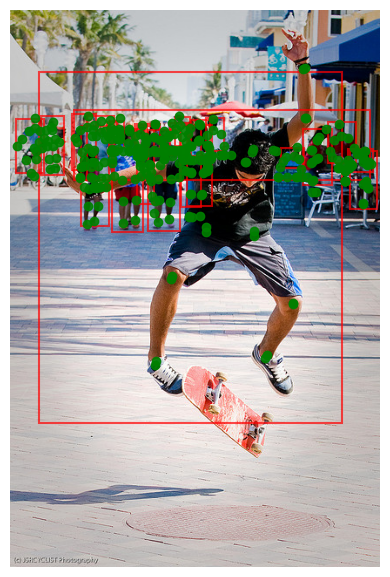

KEYPOINTS tensor([[[305.0461, 161.4229],
         [226.8898, 179.5461],
         [339.0271, 124.0438],
         [161.1932, 185.2096],
         [337.8944,  66.2760],
         [101.1600, 203.3328],
         [280.1267, 258.8351],
         [224.6244, 254.3043],
         [324.3020, 335.8588],
         [184.9799, 308.6740],
         [294.8518, 395.8919],
         [166.8567, 402.6881],
         [278.9940, 159.1575],
         [269.9324, 173.8826]],

        [[189.1615, 161.1930],
         [164.3812, 160.9081],
         [193.7188, 176.0042],
         [159.2542, 176.5738],
         [193.7188, 191.1002],
         [160.1087, 193.0941],
         [184.3194, 194.2334],
         [168.9385, 194.2334],
         [183.4649, 219.8682],
         [170.6474, 218.4440],
         [182.0407, 239.5215],
         [169.2233, 242.9395],
         [176.9137, 138.1216],
         [176.9137, 155.7812]],

        [[144.9559, 159.1102],
         [123.0498, 159.6867],
         [148.7030, 174.3868],
         [116.7085, 175.2

In [112]:
sample = dataset[0]
ex_img = sample["img_path"]
bboxes = sample.get("bboxes", None)
keypoints = sample.get("keypoints", None)

import torchvision
from PIL import Image

# Get actual image dimensions
pil_img = Image.open(ex_img)
img_w_pil, img_h_pil = pil_img.size  # PIL returns (W, H)
print(f"Image dimensions (PIL): W={img_w_pil}, H={img_h_pil}")

# Torchvision reads it as (C, H, W)
ex_img_tensor = torchvision.io.read_image(ex_img)
print(f"Image tensor shape: {ex_img_tensor.shape} = (C, H, W)")

print(keypoints.shape)

# Look at person 0 (the main person in center)
print(f"\n=== Person 0 (main person) ===")
print(f"Bounding box: {bboxes[0]}")
print(f"First 5 keypoints (current format [x, y]):")
for i in range(5):
    x, y = keypoints[0][i]
    print(f"  Joint {i}: x={x:.1f}, y={y:.1f}")

print(f"\nIf we SWAP x and y:")
for i in range(5):
    x, y = keypoints[0][i]
    print(f"  Joint {i}: x={y:.1f}, y={x:.1f}")

def show_img_with_keypoints(img_tensor, bboxes=None, keypoints=None, swap_xy=False):
    """Display image with bboxes and keypoints.
    
    Args:
        swap_xy: if True, swap x and y coordinates (in case keypoints are stored as [y,x])
    """
    img_np = img_tensor.permute(1, 2, 0).numpy()  # (H, W, C)
    
    plt.figure(figsize=(4, 8))
    plt.imshow(img_np.astype(np.uint8))
    
    # Draw bounding boxes
    if bboxes is not None:
        for i, bbox in enumerate(bboxes):
            bbox_np = bbox.numpy() if isinstance(bbox, torch.Tensor) else bbox
            x1, y1, x2, y2 = bbox_np[:4]
            if swap_xy:
                x1, y1, x2, y2 = y1, x1, y2, x2
            w = x2 - x1
            h = y2 - y1
            rect = plt.Rectangle((x1, y1), w, h, edgecolor="red", facecolor="none", linewidth=1.5, alpha=0.7)
            plt.gca().add_patch(rect)
    
    # Draw keypoints
    if keypoints is not None:
        keypoints_np = keypoints.numpy() if isinstance(keypoints, torch.Tensor) else keypoints
        for person_idx, person_kpts in enumerate(keypoints_np):
            for kpt_idx, (x, y) in enumerate(person_kpts):
                if swap_xy:
                    x, y = y, x
                plt.plot(x, y, "go", markersize=6, alpha=0.9)
    
    plt.axis("off")
    plt.tight_layout()
    plt.show()

# Try both orientations
show_img_with_keypoints(
    ex_img_tensor, 
    bboxes=sample.get("bboxes", None),
    keypoints=keypoints,
    swap_xy=False
)

print("KEYPOINTS", keypoints)



In [116]:
import random
from collections import defaultdict
from torch.utils.data import BatchSampler, SequentialSampler


class GroupedBatchSampler:
    """
    Sampler that groups indices by number of people and yields batches from same group.
    
    During training, all samples in a batch have the same N (number of people).
    This makes efficient batching possible without padding.
    """
    
    def __init__(self, dataset, batch_size, drop_last=False, shuffle=True):
        self.dataset = dataset
        self.batch_size = batch_size
        self.drop_last = drop_last
        self.shuffle = shuffle
        
        # Group indices by number of people
        self.groups = defaultdict(list)
        for idx in range(len(dataset)):
            sample = dataset[idx]
            n_people = sample["keypoints"].shape[0]
            self.groups[n_people].append(idx)
        
        # Shuffle within each group if requested
        if self.shuffle:
            for group in self.groups.values():
                random.shuffle(group)
        
        print(f"Created {len(self.groups)} groups by number of people:")
        for n_people in sorted(self.groups.keys())[:5]:
            count = len(self.groups[n_people])
            print(f"  {n_people} people: {count} images")
        if len(self.groups) > 5:
            print(f"  ... and {len(self.groups) - 5} more groups")
    
    def __iter__(self):
        """Iterate through each group, yielding complete batches."""
        for n_people in sorted(self.groups.keys()):
            indices = self.groups[n_people]
            
            # Yield complete batches from this group
            for i in range(0, len(indices), self.batch_size):
                batch = indices[i:i + self.batch_size]
                
                # Yield batch if it's full or if we're not dropping partial batches
                if len(batch) == self.batch_size or not self.drop_last:
                    yield batch
    
    def __len__(self):
        """Total number of batches."""
        total_batches = 0
        for indices in self.groups.values():
            num_batches = len(indices) // self.batch_size
            if not self.drop_last and len(indices) % self.batch_size != 0:
                num_batches += 1
            total_batches += num_batches
        return total_batches


def simple_collate(batch):
    """
    Standard collate function for uniform-N batches.
    
    Since the sampler ensures all samples have the same N,
    we can simply stack them without grouping or padding.
    """
    return {
        "image_ids": [s["image_id"] for s in batch],
        "keypoints": torch.stack([s["keypoints"] for s in batch]),  # (B, N, K, 2)
        "keypoint_scores": torch.stack([s["keypoint_scores"] for s in batch]),  # (B, N, K)
        "bboxes": torch.stack([s["bboxes"] for s in batch]) if "bboxes" in batch[0] else None,
        "bbox_scores": torch.stack([s["bbox_scores"] for s in batch]) if "bbox_scores" in batch[0] else None,
    }


# Create DataLoader with GroupedBatchSampler
grouped_loader = torch.utils.data.DataLoader(
    dataset,
    batch_sampler=GroupedBatchSampler(dataset, batch_size=16, shuffle=True, drop_last=False),
    collate_fn=simple_collate,
)

print(f"\nTotal batches in loader: {len(grouped_loader)}")

# Test a batch
for batch in grouped_loader:
    print(f"\nSample batch:")
    print(f"  Number of images: {len(batch['image_ids'])}")
    print(f"  Keypoints shape: {batch['keypoints'].shape}")
    print(f"  All images in batch have same N (people): {batch['keypoints'].shape[1]}")
    print(f"  Image IDs: {batch['image_ids'][:5]}...")
    break

example_batch = next(iter(grouped_loader))
print(f"\nExample batch keypoints shape: {example_batch['keypoints'].shape}")

Created 90 groups by number of people:
  1 people: 502 images
  2 people: 1461 images
  3 people: 1212 images
  4 people: 866 images
  5 people: 612 images
  ... and 85 more groups

Total batches in loader: 560

Sample batch:
  Number of images: 16
  Keypoints shape: torch.Size([16, 1, 14, 2])
  All images in batch have same N (people): 1
  Image IDs: [108939, 107724, 102963, 102650, 119512]...

Example batch keypoints shape: torch.Size([16, 1, 14, 2])


In [115]:
# Training loop example
def simple_refiner_step(batch):
    """
    Example training step with uniform-N batch.
    
    All images in the batch have the same number of people (N),
    so tensors have uniform shape: (B, N, K, 2)
    """
    keypoints = batch["keypoints"]  # (B, N, K, 2)
    scores = batch["keypoint_scores"]  # (B, N, K)
    
    B, N, K, _ = keypoints.shape
    
    # Your graph refiner can now:
    # 1. Build a graph with N nodes per image (uniform size)
    # 2. Process all B images in parallel without padding
    # 3. Use batch normalization, etc. without masking
    
    # Dummy refinement
    refined = keypoints.clone()
    
    return {
        "refined_keypoints": refined,
        "batch_size": B,
        "n_people": N,
    }


# Process multiple batches, showing that each batch has uniform N
print("Processing batches (note: N is consistent within batch but varies across batches):\n")
for batch_idx, batch in enumerate(grouped_loader):
    if batch_idx >= 5:
        break
    
    result = simple_refiner_step(batch)
    B, N = result["batch_size"], result["n_people"]
    print(f"Batch {batch_idx}: B={B} images × N={N} people → keypoints {result['refined_keypoints'].shape}")


Processing batches (note: N is consistent within batch but varies across batches):

Batch 0: B=16 images × N=1 people → keypoints torch.Size([16, 1, 14, 2])
Batch 1: B=16 images × N=1 people → keypoints torch.Size([16, 1, 14, 2])
Batch 2: B=16 images × N=1 people → keypoints torch.Size([16, 1, 14, 2])
Batch 3: B=16 images × N=1 people → keypoints torch.Size([16, 1, 14, 2])
Batch 4: B=16 images × N=1 people → keypoints torch.Size([16, 1, 14, 2])
